# F20: Endelige differanser i 1D -- direkte løsning, Jacobi og Gauss-Seidel

I denne notatboken implementerer vi de numeriske metodene fra kompendiets kapittel 3.3:

1. **Direkte løsning** av et to-punkts randverdiproblem (RVP) med Dirichlet-betingelser, ved å sette opp og løse det tridiagonale likningssystemet $A\vec U=\vec b$ (se "To-punkts randverdiproblem med Dirichlet-betingelser").
2. **Jacobi-iterasjon** og **Gauss-Seidel-iterasjon**, som løser det samme systemet iterativt uten å bygge opp $A$ eksplisitt (se "Iterative metoder: Jacobi- og Gauss-Seidel-iterasjon").

Vi tester kodene på eksemplene fra kompendiet, slik at du kan sammenligne med de håndregnede verdiene der.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Direkte løsning av RVP med Dirichlet-betingelser

Vi løser
$$
u'' + p\,u' + q\,u = r(x), \qquad a\le x\le b, \qquad u(a)=u_a,\ u(b)=u_b,
$$
for konstante $p,q$. Koeffisientene i det tridiagonale systemet er (som i kompendiet)
$$
v = 1-\tfrac{h}{2}p, \qquad d=-2+h^2q, \qquad w=1+\tfrac{h}{2}p.
$$

In [2]:
def los_RVP_direkte(p, q, r_func, a, b, ua, ub, N):
    '''Løser u'' + p u' + q u = r(x) på [a,b] med u(a)=ua, u(b)=ub,
    ved å sette opp og løse det tridiagonale systemet A U = b direkte.
    p, q: konstanter. r_func: funksjon r(x). N: antall delintervaller.
    Returnerer (x, U) der U[i] er den numeriske tilnærmingen til u(x[i]).'''
    h = (b - a) / N
    x = a + h * np.arange(N + 1)

    # Koeffisientene i den tridiagonale matrisen, som i kompendiet
    v = 1 - h / 2 * p
    d = -2 + h**2 * q
    w = 1 + h / 2 * p

    A = np.zeros((N + 1, N + 1))
    bvec = np.zeros(N + 1)

    # Randbetingelser: de to første/siste likningene er trivielle U_0=ua, U_N=ub
    A[0, 0] = 1.0
    bvec[0] = ua
    A[N, N] = 1.0
    bvec[N] = ub

    # Indre punkter: diskretisert RVP
    for i in range(1, N):
        A[i, i - 1] = v
        A[i, i] = d
        A[i, i + 1] = w
        bvec[i] = h**2 * r_func(x[i])

    U = np.linalg.solve(A, bvec)
    return x, U

### Test: Eksempel fra kompendiet

Vi tester på eksemplet fra "To-punkts randverdiproblem med Dirichlet-betingelser" i kompendiet:
$$
u'' + 2u' - 3u = 9x, \qquad u(0)=1, \qquad u(1)=e^{-3}+2e-5,
$$
med eksakt løsning $u(x) = e^{-3x} + 2e^x - 3x - 2$. Med $N=4$ skal vi få $U_1\approx 0.293176$, $U_2\approx 0.025557$, $U_3\approx 0.093820$ -- akkurat som i kompendiet.

In [3]:
def u_eksakt(x):
    return np.exp(-3*x) + 2*np.exp(x) - 3*x - 2

ua, ub = u_eksakt(0.0), u_eksakt(1.0)
x, U = los_RVP_direkte(p=2, q=-3, r_func=lambda x: 9*x, a=0, b=1, ua=ua, ub=ub, N=4)

print("x  :", np.round(x, 4))
print("U  :", np.round(U, 6))
print("u  :", np.round(u_eksakt(x), 6))
print("Stemmer dette med kompendiets U_1, U_2, U_3?", np.allclose(U[1:4], [0.293176, 0.025557, 0.093820], atol=1e-5))

x  : [0.   0.25 0.5  0.75 1.  ]
U  : [1.       0.293176 0.025557 0.09382  0.486351]
u  : [1.       0.290417 0.020573 0.089399 0.486351]
Stemmer dette med kompendiets U_1, U_2, U_3? True


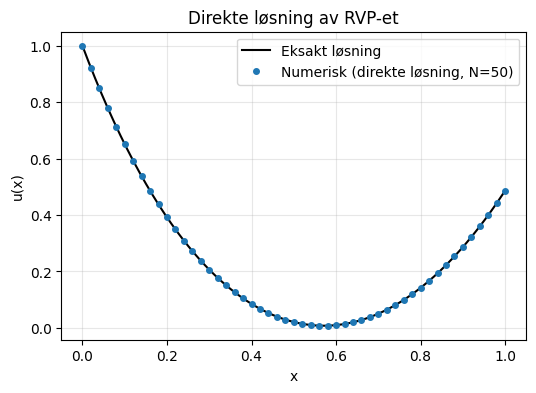

In [4]:
# Samme eksempel, men med flere punkter, plottet mot den eksakte løsningen
x_fin, U_fin = los_RVP_direkte(p=2, q=-3, r_func=lambda x: 9*x, a=0, b=1, ua=ua, ub=ub, N=50)
x_plot = np.linspace(0, 1, 400)

plt.figure(figsize=(6, 4))
plt.plot(x_plot, u_eksakt(x_plot), 'k-', label="Eksakt løsning")
plt.plot(x_fin, U_fin, 'o', ms=4, label="Numerisk (direkte løsning, N=50)")
plt.xlabel("x"); plt.ylabel("u(x)")
plt.title("Direkte løsning av RVP-et")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 2. Jacobi-iterasjon

I stedet for å løse $A\vec U=\vec b$ direkte, kan vi iterere oppdateringsformelen
$$
U_i^{(m+1)} = \frac{1}{d}\Big(h^2r(x_i) - vU_{i-1}^{(m)} - wU_{i+1}^{(m)}\Big)
$$
til konvergens. Vi starter med $U_i^{(0)}=0$ i de indre punktene (og de gitte randverdiene i endepunktene), slik som i kompendiets eksempel.

In [5]:
def jacobi_RVP(p, q, r_func, a, b, ua, ub, N, tol=1e-8, maxit=100_000):
    '''Løser samme RVP som los_RVP_direkte, men med Jacobi-iterasjon.
    Returnerer (x, U, antall_iterasjoner, historikk_over_endring).'''
    h = (b - a) / N
    x = a + h * np.arange(N + 1)
    v = 1 - h / 2 * p
    d = -2 + h**2 * q
    w = 1 + h / 2 * p

    U = np.zeros(N + 1)
    U[0], U[-1] = ua, ub
    historikk = []

    for it in range(maxit):
        Unytt = U.copy()
        for i in range(1, N):
            Unytt[i] = (h**2 * r_func(x[i]) - v * U[i - 1] - w * U[i + 1]) / d
        endring = np.max(np.abs(Unytt - U))
        historikk.append(endring)
        U = Unytt
        if endring < tol:
            break

    return x, U, it + 1, historikk

## 3. Gauss-Seidel-iterasjon

Samme oppdateringsformel, men vi bruker oppdaterte verdier $U_{i-1}^{(m+1)}$ med én gang de er beregnet.

In [6]:
def gauss_seidel_RVP(p, q, r_func, a, b, ua, ub, N, tol=1e-8, maxit=100_000):
    '''Løser samme RVP som los_RVP_direkte, men med Gauss-Seidel-iterasjon.
    Returnerer (x, U, antall_iterasjoner, historikk_over_endring).'''
    h = (b - a) / N
    x = a + h * np.arange(N + 1)
    v = 1 - h / 2 * p
    d = -2 + h**2 * q
    w = 1 + h / 2 * p

    U = np.zeros(N + 1)
    U[0], U[-1] = ua, ub
    historikk = []

    for it in range(maxit):
        endring = 0.0
        for i in range(1, N):
            gammel = U[i]
            # Her brukes U[i-1] som allerede er oppdatert denne runden
            U[i] = (h**2 * r_func(x[i]) - v * U[i - 1] - w * U[i + 1]) / d
            endring = max(endring, abs(U[i] - gammel))
        historikk.append(endring)
        if endring < tol:
            break

    return x, U, it + 1, historikk

### Test: eksemplet fra kompendiet ("Jacobi vs. Gauss-Seidel")

$u''=0$ på $[0,2]$ med $u(0)=20$, $u(2)=50$ -- eksakt løsning $u(x)=20+15x$. Kompendiet oppgir at Jacobi trenger 398 iterasjoner og Gauss-Seidel 201 iterasjoner med $N=10$ og toleranse $10^{-8}$.

In [7]:
p, q = 0.0, 0.0
r_func = lambda x: 0.0
a, b, ua, ub, N = 0.0, 2.0, 20.0, 50.0, 10

xj, Uj, itj, histj = jacobi_RVP(p, q, r_func, a, b, ua, ub, N)
xg, Ug, itg, histg = gauss_seidel_RVP(p, q, r_func, a, b, ua, ub, N)

u_eksakt_lin = lambda x: 20 + 15*x

print(f"Jacobi:       {itj} iterasjoner, maks feil = {np.max(np.abs(Uj - u_eksakt_lin(xj))):.2e}")
print(f"Gauss-Seidel: {itg} iterasjoner, maks feil = {np.max(np.abs(Ug - u_eksakt_lin(xg))):.2e}")

Jacobi:       398 iterasjoner, maks feil = 9.60e-08
Gauss-Seidel: 201 iterasjoner, maks feil = 8.69e-08


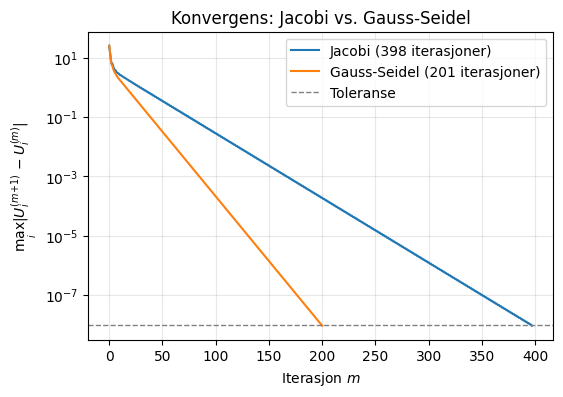

In [8]:
# Konvergensplott: hvor fort minker endringen per iterasjon?
plt.figure(figsize=(6, 4))
plt.semilogy(histj, label=f"Jacobi ({itj} iterasjoner)")
plt.semilogy(histg, label=f"Gauss-Seidel ({itg} iterasjoner)")
plt.axhline(1e-8, color='gray', ls='--', lw=1, label="Toleranse")
plt.xlabel("Iterasjon $m$"); plt.ylabel(r"$\max_i|U_i^{(m+1)}-U_i^{(m)}|$")
plt.title("Konvergens: Jacobi vs. Gauss-Seidel")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

Gauss-Seidel konvergerer om lag dobbelt så raskt som Jacobi her -- akkurat som forklart i kompendiet.

## 4. Jacobi/Gauss-Seidel med $r(x)\neq0$ (Poisson-type problemer)

De samme funksjonene fungerer uendret for $r(x)\neq 0$, siden vi bare har brukt $r(x_i)$ i oppdateringsformelen. Her tester vi med et annet eksempel: $u'' = -\cos(3x)$ på $[0,2]$, med $u(0)=0$, $u(2)=1$.

Jacobi brukte 4121 iterasjoner, Gauss-Seidel brukte 2042 iterasjoner.
Maks avvik mellom direkte løsning og Jacobi: 1.3291589380792779e-06
Maks avvik mellom direkte løsning og Gauss-Seidel: 1.6134490444241756e-06


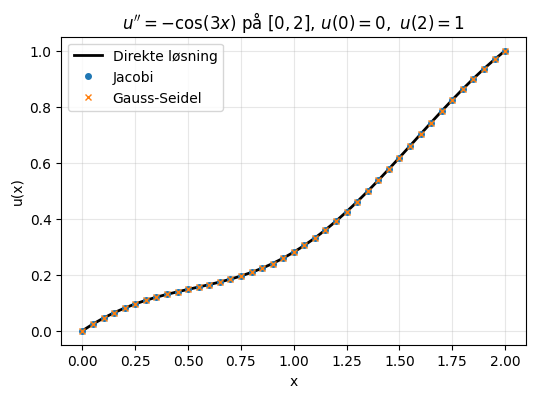

In [9]:
p2, q2 = 0.0, 0.0
r_func2 = lambda x: -np.cos(3*x)
a2, b2, ua2, ub2, N2 = 0.0, 2.0, 0.0, 1.0, 40

x_dir, U_dir = los_RVP_direkte(p2, q2, r_func2, a2, b2, ua2, ub2, N2)
x_jac, U_jac, it_jac, _ = jacobi_RVP(p2, q2, r_func2, a2, b2, ua2, ub2, N2)
x_gs, U_gs, it_gs, _ = gauss_seidel_RVP(p2, q2, r_func2, a2, b2, ua2, ub2, N2)

print(f"Jacobi brukte {it_jac} iterasjoner, Gauss-Seidel brukte {it_gs} iterasjoner.")
print("Maks avvik mellom direkte løsning og Jacobi:", np.max(np.abs(U_dir - U_jac)))
print("Maks avvik mellom direkte løsning og Gauss-Seidel:", np.max(np.abs(U_dir - U_gs)))

plt.figure(figsize=(6, 4))
plt.plot(x_dir, U_dir, 'k-', lw=2, label="Direkte løsning")
plt.plot(x_jac, U_jac, 'o', ms=4, label="Jacobi")
plt.plot(x_gs, U_gs, 'x', ms=5, label="Gauss-Seidel")
plt.xlabel("x"); plt.ylabel("u(x)")
plt.title(r"$u''=-\cos(3x)$ på $[0,2]$, $u(0)=0,\ u(2)=1$")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Oppsummering

* Direkte løsning (`np.linalg.solve`) er eksakt (opp til avrundingsfeil) og rask for små 1D-problemer.
* Jacobi- og Gauss-Seidel-iterasjon unngår å bygge opp hele matrisen $A$, og generaliserer direkte til flere dimensjoner (se F21).
* Gauss-Seidel bruker oppdatert informasjon underveis, og konvergerer derfor typisk om lag dobbelt så raskt som Jacobi.
* Begge de iterative metodene fungerer uendret for $r(x)\neq 0$ (Poisson-type problemer), ikke bare for Laplace-likningen ($r=0$).